# 训练 AudioNet

用 ESC-50 的 fold 1–3 训练，fold 4 做验证。训练结束后模型写到 `outputs/audionet.ckpt`。
测试请运行 `test.ipynb`，不要在这里使用 fold 5。


## Reproducible Deep Learning (PhD course, Data Science)
### Lecture 1: deep learning recap

A convolutional neural network for the ESC-50 dataset: https://github.com/karolpiczak/ESC-50.


In [20]:
import torch, torchaudio
from torch import nn
from torch.nn import functional as F


In [21]:
import pytorch_lightning as pl
from torchmetrics.functional import accuracy


In [22]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd


In [23]:
torch.cuda.is_available()


False

### Step 1: Some experiments in audio loading and transformation

The code in this section is just for experimentation.


In [24]:
# Root folder of ESC-50, containing the subfolders 'audio' and 'meta'.
datapath = Path('ESC-50-master/ESC-50-master')


In [25]:
datapath.exists()


True

In [26]:
csv = pd.read_csv(datapath / Path('meta/esc50.csv'))
csv.head()


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [27]:
x, sr = torchaudio.load(datapath / 'audio' / csv.iloc[0, 0], normalize=True)
x.shape


torch.Size([1, 220500])

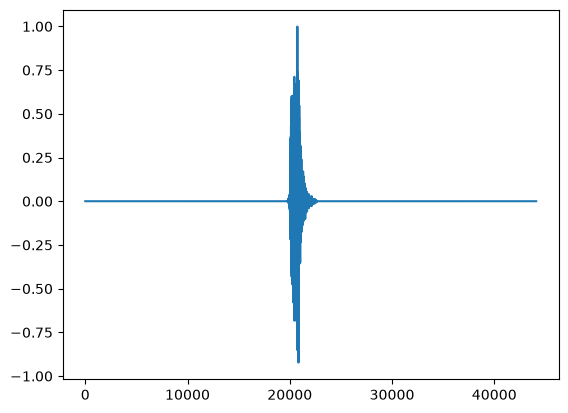

In [28]:
plt.plot(x[0, ::5])


/Users/atharva/Desktop/Pettichat Internship/esc50-my-first-run/.venv311/lib/python3.11/site-packages/torchaudio/functional/functional.py:584: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (201) may be set too low.
  warnings.warn(


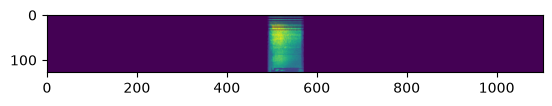

In [29]:
h = torchaudio.transforms.MelSpectrogram(sample_rate=sr)(x)
h = torchaudio.transforms.AmplitudeToDB()(h)
plt.imshow(h[0])


### Step 2: Putting together data loading and preprocessing


In [30]:
class ESC50Dataset(torch.utils.data.Dataset):
    # Simple class to load the desired folders inside ESC-50

    def __init__(self, path: Path = Path('ESC-50-master/ESC-50-master'),
                 sample_rate: int = 8000,
                 folds = [1]):
        # Load CSV & initialize all torchaudio.transforms:
        # Resample --> MelSpectrogram --> AmplitudeToDB
        self.path = path
        self.csv = pd.read_csv(path / Path('meta/esc50.csv'))
        self.csv = self.csv[self.csv['fold'].isin(folds)]
        self.resample = torchaudio.transforms.Resample(
            orig_freq=44100, new_freq=sample_rate
        )
        self.melspec = torchaudio.transforms.MelSpectrogram(
            sample_rate=sample_rate)
        self.db = torchaudio.transforms.AmplitudeToDB(top_db=80)

    def __getitem__(self, index):
        # Returns (xb, yb) pair, after applying all transformations on the audio file.
        row = self.csv.iloc[index]
        wav, _ = torchaudio.load(self.path / 'audio' / row['filename'])
        label = row['target']
        xb = self.db(
            self.melspec(
                self.resample(wav)
            )
        )
        return xb, label

    def __len__(self):
        # Returns length
        return len(self.csv)


In [31]:
train_data = ESC50Dataset(folds=[1, 2, 3])
val_data = ESC50Dataset(folds=[4])
len(train_data), len(val_data)


(1200, 400)

In [32]:
xb, yb = train_data[0]
xb.shape, yb


(torch.Size([1, 128, 201]), 0)

### Step 3: Build a classification model and train


In [33]:
train_loader = torch.utils.data.DataLoader(train_data, batch_size=8, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=8)


In [34]:
class AudioNet(pl.LightningModule):

    def __init__(self, n_classes = 50, base_filters = 32):
        super().__init__()
        self.save_hyperparameters()
        self.conv1 = nn.Conv2d(1, base_filters, 11, padding=5)
        self.bn1 = nn.BatchNorm2d(base_filters)
        self.conv2 = nn.Conv2d(base_filters, base_filters, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(base_filters)
        self.pool1 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(base_filters, base_filters * 2, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(base_filters * 2)
        self.conv4 = nn.Conv2d(base_filters * 2, base_filters * 4, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(base_filters * 4)
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(base_filters * 4, n_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.conv2(x)
        x = F.relu(self.bn2(x))
        x = self.pool1(x)
        x = self.conv3(x)
        x = F.relu(self.bn3(x))
        x = self.conv4(x)
        x = F.relu(self.bn4(x))
        x = self.pool2(x)
        x = F.adaptive_avg_pool2d(x, (1, 1))
        x = self.fc1(x[:, :, 0, 0])
        return x

    def training_step(self, batch, batch_idx):
        # Very simple training loop
        x, y = batch
        y_hat = self(x)
        loss = F.cross_entropy(y_hat, y)
        self.log('train_loss', loss, on_step=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y_hat = self(x)
        y_hat = torch.argmax(y_hat, dim=1)
        acc = accuracy(y_hat, y, task="multiclass", num_classes=50)
        self.log('val_acc', acc, on_epoch=True, prog_bar=True)
        return acc

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        return optimizer


In [35]:
pl.seed_everything(0)


Seed set to 0


0

In [36]:
# Check that the network works on a single mini-batch.
audionet = AudioNet()
xb, yb = next(iter(train_loader))
audionet(xb).shape


torch.Size([8, 50])

In [37]:
trainer = pl.Trainer(accelerator="auto", devices=1, max_epochs=25)
trainer.fit(audionet, train_loader, val_loader)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

   | Name  | Type        | Params | Mode  | FLOPs
-------------------------------------------------------
0  | conv1 | Conv2d      | 3.9 K  | train | 0    
1  | bn1   | BatchNorm2d | 64     | train | 0    
2  | conv2 | Conv2d      | 9.2 K  | train | 0    
3  | bn2   | BatchNorm2d | 64     | train | 0    
4  | pool1 | MaxPool2d   | 0      | train | 0    
5  | conv3 | Conv2d      | 18.5 K | train | 0    
6  | bn3   | BatchNorm2d | 128    | train | 0    
7  | conv4 | Conv2d      | 73

/Users/atharva/Desktop/Pettichat Internship/esc50-my-first-run/.venv311/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/atharva/Desktop/Pettichat Internship/esc50-my-first-run/.venv311/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 0: 100%|██████████████████████████████████████████████████████████████| 150/150 [00:06<00:00, 24.12it/s, v_num=1]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Epoch 1: 100%|███████████████████████████████████████████████| 150/150 [00:06<00:00, 24.04it/s, v_num=1, val_acc=0.155]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Epoch 2: 100%|███████████████████████████████████████████████| 150/150 [00:06<00:00, 23.89it/s, v_num=1, val_acc=0.215]
Validation: |                                                                                    | 0/? [00:00<?, ?it/s]
Validation: |                           

`Trainer.fit` stopped: `max_epochs=25` reached.


Epoch 24: 100%|██████████████████████████████████████████████| 150/150 [00:07<00:00, 19.50it/s, v_num=1, val_acc=0.495]


In [38]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

ckpt_path = output_dir / "audionet.ckpt"
trainer.save_checkpoint(ckpt_path)
print(ckpt_path.resolve())


`weights_only` was not set, defaulting to `False`.


/Users/atharva/Desktop/Pettichat Internship/esc50-my-first-run/outputs/audionet.ckpt
